# 02. RAG thực thi cho kiến thức tiểu đường
Chương 4.3 và 4.4. Corpus NIDDK tiếng Anh đã tải; truy hồi BM25/dense/hybrid; mô hình FLAN-T5-small thực sự sinh câu trả lời trên CPU.

Tập đánh giá nhỏ do người viết xây từ corpus để minh họa, không phải benchmark y khoa độc lập. Notebook và thảo luận viết bằng tiếng Việt; câu hỏi và đầu ra đánh giá giữ tiếng Anh vì nguồn/model baseline. Không tự nhận đã đánh giá khả năng song ngữ hoặc an toàn lâm sàng.

In [1]:
from pathlib import Path
import sys, json, time, random, platform, importlib.metadata as metadata
ROOT = Path.cwd().resolve()
while not (ROOT / 'data/chapter04').exists():
    if ROOT.parent == ROOT: raise RuntimeError('Không tìm thấy thư mục dự án')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / 'data/chapter04'
RESULT = ROOT / 'results/chapter04'
FIG = ROOT / 'docs/report_chapter_04'
RESULT.mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
random.seed(42); np.random.seed(42)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
environment = {'python': platform.python_version(), 'platform': platform.platform(),
    'packages': {p: metadata.version(p) for p in ['numpy','pandas','networkx','torch','transformers','nbclient','fastapi']}}
display(pd.DataFrame(environment['packages'].items(), columns=['Thư viện','Phiên bản']))

,Thư viện,Phiên bản
0,numpy,2.5.2
1,pandas,3.0.5
2,networkx,3.6.1
3,torch,2.13.0
4,transformers,4.57.6
5,nbclient,0.11.0
6,fastapi,0.141.1


## 1. Tạo dataset hỏi đáp minh họa có bằng chứng

In [2]:
corpus = [json.loads(x) for x in (DATA/'diabetes_corpus.jsonl').read_text(encoding='utf-8').splitlines()]
# question, source substring, accepted references; no QA enters the retrieval corpus.
specs = [
 ('What organ makes insulin?','Insulin is a hormone made by the pancreas',['pancreas','the pancreas']),
 ('Which hormone helps glucose enter cells?','Insulin is a hormone made by the pancreas',['insulin']),
 ('What is the most common type of diabetes?','Type 2 diabetes is the most common',['type 2 diabetes','type 2']),
 ('When does gestational diabetes develop?','develops during pregnancy',['during pregnancy','pregnancy']),
 ('Are glucose levels in prediabetes above normal?','People with prediabetes have blood glucose',['yes','higher than normal']),
 ('What attacks insulin-producing cells in type 1 diabetes?','Your immune system attacks',['the immune system','immune system']),
 ('What causes monogenic diabetes?','a change in a single gene',['a change in a single gene','single gene mutation']),
 ('How many months are reflected in an A1C blood test?','The A1C test is a blood test',['3 months','the last 3 months','three months']),
 ('How many hours should a person fast before the fasting plasma glucose test?','fasted for at least 8 hours',['at least 8 hours','8 hours']),
 ('Can an over-the-counter blood glucose meter diagnose diabetes?','cannot diagnose diabetes',['no']),
 ('During which pregnancy weeks is gestational diabetes screening recommended?','between 24 and 28 weeks',['24 to 28 weeks','between 24 and 28 weeks']),
 ('Which health measure corresponds to B in the diabetes ABCs?','High blood pressure can damage',['blood pressure']),
 ('Which health measure corresponds to C in the diabetes ABCs?','Cholesterol is a fat',['cholesterol']),
 ('How many minutes of moderate activity per week does this source suggest?','at least 150 minutes',['150 minutes','at least 150 minutes']),
 ('How many hours of sleep per night should most adults aim for according to this source?','about 7 to 8 hours',['7 to 8 hours','about 7 to 8 hours']),
 ('Can type 2 diabetes occur during childhood?','even during childhood',['yes'])]
qa=[]
for i,(question,needle,refs) in enumerate(specs):
    matches=[x for x in corpus if needle.lower() in x['text'].lower()]
    assert matches,needle
    qa.append({'id':f'DM{i+1:02d}','question':question,'references':refs,'gold_ids':[matches[0]['id']],
               'annotation':'authored demonstration; source-anchored; not independently reviewed'})
(DATA/'diabetes_qa_demo.json').write_text(json.dumps(qa,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame(qa)[['id','question','references']])

,id,question,references
0,DM01,What organ makes insulin?,"[pancreas, the pancreas]"
1,DM02,Which hormone helps glucose enter cells?,[insulin]
2,DM03,What is the most common type of diabetes?,"[type 2 diabetes, type 2]"
3,DM04,When does gestational diabetes develop?,"[during pregnancy, pregnancy]"
4,DM05,Are glucose levels in prediabetes above normal?,"[yes, higher than normal]"
5,DM06,What attacks insulin-producing cells in type 1...,"[the immune system, immune system]"
6,DM07,What causes monogenic diabetes?,"[a change in a single gene, single gene mutation]"
7,DM08,How many months are reflected in an A1C blood ...,"[3 months, the last 3 months, three months]"
8,DM09,How many hours should a person fast before the...,"[at least 8 hours, 8 hours]"
9,DM10,Can an over-the-counter blood glucose meter di...,[no]


## 2. Lập chỉ mục BM25 và vector từ mô hình pretrained thật

In [3]:
from src.chapter04.retrieval import BM25, Encoder, DenseRetriever, hybrid_search, retrieval_metrics
from src.chapter04.rag import LocalGenerator, normalized_answer, token_f1
encoder=Encoder(ROOT/'models/chapter04/embedding')
bm25=BM25(corpus)
dense=DenseRetriever(corpus,encoder,RESULT/'diabetes_embeddings.npy')
query_vectors=encoder.encode([x['question'] for x in qa])
print('Corpus vectors:',dense.vectors.shape,'; Query vectors:',query_vectors.shape)
display(pd.DataFrame(hybrid_search(bm25,dense,qa[0]['question'],3))[['id','text','source_url']])

Corpus vectors: (183, 384) ; Query vectors: (16, 384)


,id,text,source_url
0,what-is-diabetes:14,"If you have type 1 diabetes , your body makes ...",https://www.niddk.nih.gov/health-information/d...
1,symptoms-causes:54,Type 2 diabetes is the most common form of dia...,https://www.niddk.nih.gov/health-information/d...
2,what-is-diabetes:9,Insulin is a hormone made by the pancreas that...,https://www.niddk.nih.gov/health-information/d...


## 3. Đánh giá truy hồi trên 16 câu hỏi

In [4]:
retrieval=[]; rankings={}
for method in ['bm25','dense','hybrid']:
    started=time.perf_counter(); current=[]
    for i,item in enumerate(qa):
        if method=='bm25': hits=bm25.search(item['question'],5)
        elif method=='dense': hits=dense.search(item['question'],5,query_vector=query_vectors[i])
        else: hits=hybrid_search(bm25,dense,item['question'],5,query_vector=query_vectors[i])
        current.append([x['id'] for x in hits])
    metric=retrieval_metrics(current,[set(x['gold_ids']) for x in qa]);metric.update(method=method,seconds=time.perf_counter()-started)
    retrieval.append(metric); rankings[method]=current
display(pd.DataFrame(retrieval).set_index('method').round(4))

,questions,hit_at_1,hit_at_5,recall_at_5,mrr_at_5,complete_at_5,seconds
method,,,,,,,
bm25,16,0.3750,0.6875,0.6875,0.5104,0.6875,0.0197
dense,16,0.5000,0.8125,0.8125,0.6354,0.8125,0.0100
hybrid,16,0.4375,0.8750,0.8750,0.6146,0.8750,0.0369


## 4. Sinh thật: không context, hybrid RAG và gold-context oracle

In [5]:
generator=LocalGenerator(ROOT/'models/chapter04/generator')
lookup={x['id']:x for x in corpus}; generations=[]
for i,item in enumerate(qa):
    for mode in ['no_context','hybrid_rag','gold_context_oracle']:
        evidence=None if mode=='no_context' else [lookup[x] for x in (rankings['hybrid'][i][:3] if mode=='hybrid_rag' else item['gold_ids'])]
        started=time.perf_counter();answer=generator.generate(item['question'],evidence)
        generations.append({'id':item['id'],'question':item['question'],'mode':mode,'answer':answer,
            'references':item['references'],'exact_match':max(normalized_answer(answer)==normalized_answer(r) for r in item['references']),
            'token_f1':max(token_f1(answer,r) for r in item['references']),
            'evidence_ids':[x['id'] for x in evidence or []],'seconds':time.perf_counter()-started})
generation_table=pd.DataFrame(generations)
display(generation_table[['id','mode','answer','exact_match','token_f1']].head(15))
generation_metrics=generation_table.groupby('mode').agg(questions=('id','size'),exact_match=('exact_match','mean'),token_f1=('token_f1','mean'),mean_seconds=('seconds','mean')).reset_index()
display(generation_metrics.round(4))

,id,mode,answer,exact_match,token_f1
0,DM01,no_context,insulin,False,0.0
1,DM01,hybrid_rag,pancreas,True,1.0
2,DM01,gold_context_oracle,pancreas,True,1.0
3,DM02,no_context,Glucose,False,0.0
4,DM02,hybrid_rag,insulin,True,1.0
5,DM02,gold_context_oracle,insulin,True,1.0
6,DM03,no_context,diabetes,False,0.5
7,DM03,hybrid_rag,Type 2 diabetes,True,1.0
8,DM03,gold_context_oracle,Type 2 diabetes,True,1.0
9,DM04,no_context,onset of adolescence,False,0.0


,mode,questions,exact_match,token_f1,mean_seconds
0,gold_context_oracle,16,0.5625,0.8072,0.6699
1,hybrid_rag,16,0.3125,0.5466,0.8476
2,no_context,16,0.0625,0.0938,0.4730


## 5. Biểu đồ, lỗi và lưu bằng chứng thực thi

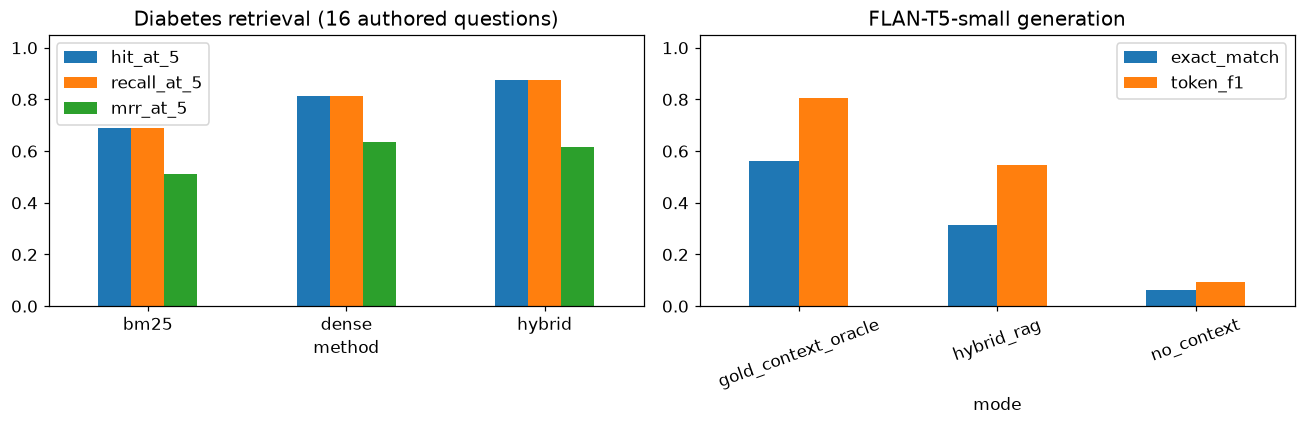

,question,answer,references,token_f1
10,When does gestational diabetes develop?,when you are pregnant,"[during pregnancy, pregnancy]",0.000000
13,Are glucose levels in prediabetes above normal?,hyperglycemia,"[yes, higher than normal]",0.000000
19,What causes monogenic diabetes?,genetic testing,"[a change in a single gene, single gene mutation]",0.000000
22,How many months are reflected in an A1C blood ...,3,"[3 months, the last 3 months, three months]",0.666667
25,How many hours should a person fast before the...,8,"[at least 8 hours, 8 hours]",0.666667
31,During which pregnancy weeks is gestational di...,24 and 28 weeks,"[24 to 28 weeks, between 24 and 28 weeks]",0.888889


In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
pd.DataFrame(retrieval).set_index('method')[['hit_at_5','recall_at_5','mrr_at_5']].plot.bar(ax=axes[0],ylim=(0,1.05))
axes[0].set_title('Diabetes retrieval (16 authored questions)');axes[0].tick_params(axis='x',rotation=0)
generation_metrics.set_index('mode')[['exact_match','token_f1']].plot.bar(ax=axes[1],ylim=(0,1.05))
axes[1].set_title('FLAN-T5-small generation');axes[1].tick_params(axis='x',rotation=20)
fig.tight_layout();fig.savefig(FIG/'diabetes_rag_metrics.png',bbox_inches='tight');plt.show()
display(generation_table[(generation_table['mode']=='hybrid_rag') & ~generation_table['exact_match']][['question','answer','references','token_f1']].head(6))
result={'questions':len(qa),'retrieval':retrieval,'generation':generation_metrics.to_dict('records'),
        'model':'google/flan-t5-small','embedding_model':'sentence-transformers/all-MiniLM-L6-v2',
        'generation_outputs':generations,'environment':environment,'benchmark':'authored demonstration, not clinical validation'}
(RESULT/'diabetes_rag_results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
generation_table.to_csv(RESULT/'diabetes_generation_predictions.csv',index=False,encoding='utf-8-sig')

## Nhận xét
Gold-context là điều kiện oracle tách lỗi truy hồi khỏi lỗi sinh; không phải một hệ thống tự tìm hoàn hảo. EM/F1 đo trùng khớp từ với đáp án ngắn và có thể phạt câu đúng nhưng diễn đạt khác. Citation IDs cho biết nguồn context; chưa chứng minh từng câu sinh được nguồn hỗ trợ. Giữ nguyên câu trả lời sai trong CSV và báo cáo.